## 1. 데이터 불러오기
데이터 크기와 일부 행을 확인합니다.

In [81]:
import pandas as pd

df = pd.read_csv("hotel_bookings.csv")
print(df.shape)
df.head()

(457, 14)


,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
0,Resort Hotel,263,Dec,2,0.0,0,KOR,Online,Refundable,Transient,227.0,0,1,0
1,City Hotel,282,Feb,2,0.0,0,GBR,Agent,No Deposit,Contract,328.0,1,2,1
2,Resort Hotel,26,Jun,2,1.0,0,FRA,Corporate,Refundable,Group,195.0,5,2,1
3,Resort Hotel,225,Feb,2,0.0,0,FRA,Offline,No Deposit,Group,1500.0,2,4,1
4,Resort Hotel,276,Feb,2,2.0,0,KOR,Corporate,No Deposit,Group,111.0,1,2,1


## 컬럼명 한글 안내
아래 표에서 원본 컬럼명과 한글 뜻을 확인할 수 있습니다. 분석 코드에서 쓰는 원본 컬럼명은 그대로 유지합니다.

In [82]:
column_ko = {
    "hotel": "호텔 유형",
    "lead_time": "예약 리드타임(숙박일까지 남은 일수)",
    "arrival_month": "도착 월",
    "adults": "성인 수",
    "children": "어린이 수",
    "babies": "유아 수",
    "country": "고객 국가",
    "market_segment": "예약 경로 유형",
    "deposit_type": "보증금 유형",
    "customer_type": "고객 유형",
    "adr": "1박 평균 객실 요금",
    "previous_cancellations": "이전 취소 횟수",
    "special_requests": "특별 요청 수",
    "is_canceled": "예약 취소 여부(1=취소, 0=미취소)"
}

column_guide = pd.DataFrame({"컬럼명": column_ko.keys(), "한글 뜻": column_ko.values()})
display(column_guide)
display(df.head().rename(columns=column_ko))

,컬럼명,한글 뜻
0,hotel,호텔 유형
1,lead_time,예약 리드타임(숙박일까지 남은 일수)
2,arrival_month,도착 월
3,adults,성인 수
4,children,어린이 수
5,babies,유아 수
6,country,고객 국가
7,market_segment,예약 경로 유형
8,deposit_type,보증금 유형
9,customer_type,고객 유형


,호텔 유형,예약 리드타임(숙박일까지 남은 일수),도착 월,성인 수,어린이 수,유아 수,고객 국가,예약 경로 유형,보증금 유형,고객 유형,1박 평균 객실 요금,이전 취소 횟수,특별 요청 수,"예약 취소 여부(1=취소, 0=미취소)"
0,Resort Hotel,263,Dec,2,0.0,0,KOR,Online,Refundable,Transient,227.0,0,1,0
1,City Hotel,282,Feb,2,0.0,0,GBR,Agent,No Deposit,Contract,328.0,1,2,1
2,Resort Hotel,26,Jun,2,1.0,0,FRA,Corporate,Refundable,Group,195.0,5,2,1
3,Resort Hotel,225,Feb,2,0.0,0,FRA,Offline,No Deposit,Group,1500.0,2,4,1
4,Resort Hotel,276,Feb,2,2.0,0,KOR,Corporate,No Deposit,Group,111.0,1,2,1


## 2. 결측값 확인 및 처리
국가와 보증금 유형은 미기록 상태를 나타내도록 Unknown으로 채웁니다. 어린이 수와 객실 요금(ADR)은 중앙값으로 대체합니다.

In [83]:
print(df.isna().sum()[df.isna().sum() > 0])

df["country"] = df["country"].fillna("Unknown")
df["deposit_type"] = df["deposit_type"].fillna("Unknown")
df["children"] = df["children"].fillna(df["children"].median())
df["adr"] = df["adr"].fillna(df["adr"].median())

print("남은 결측값:", df.isna().sum().sum())

children        8
country         7
deposit_type    4
adr             5
dtype: int64
남은 결측값: 0


## 3. 입력 변수와 종속변수 분리
is_canceled를 예측할 종속변수 y로 분리합니다.

In [84]:
X = df.drop(columns="is_canceled")
y = df["is_canceled"]
print(X.shape, y.shape)

(457, 13) (457,)


## 4. 학습 데이터와 테스트 데이터 분할
종속변수의 비율을 유지하며 데이터를 나눕니다.

In [85]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(319, 13) (138, 13)


## 5. 원핫 인코딩
학습 데이터로 범주형 열을 인코딩하고, 같은 열 구성을 테스트 데이터에 적용합니다.

In [86]:
X_train_encoded = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test_encoded = pd.get_dummies(X_test, drop_first=True, dtype=int)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
print(X_train_encoded.shape, X_test_encoded.shape)
X_train_encoded.head()

(319, 33) (138, 33)


,lead_time,adults,children,babies,adr,previous_cancellations,special_requests,hotel_Resort Hotel,arrival_month_Aug,arrival_month_Dec,...,country_USA,country_Unknown,market_segment_Corporate,market_segment_Offline,market_segment_Online,deposit_type_Non Refund,deposit_type_Refundable,deposit_type_Unknown,customer_type_Group,customer_type_Transient
32,190,2,0.0,0,169.0,3,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
324,189,1,0.0,0,318.0,3,1,0,0,0,...,0,0,1,0,0,1,0,0,1,0
247,75,3,0.0,0,62.0,1,4,1,0,1,...,0,0,0,0,1,1,0,0,0,0
309,201,2,0.0,0,62.0,0,4,0,0,0,...,0,0,0,0,1,0,0,0,1,0
115,274,2,0.0,0,309.0,5,4,0,0,0,...,0,1,0,1,0,0,0,0,0,0


## 6. KNN 모델 학습 및 평가

In [87]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_model = KNeighborsClassifier()
knn_model.fit(X_train_encoded, y_train)
knn_pred = knn_model.predict(X_test_encoded)
knn_score = accuracy_score(y_test, knn_pred)
print("KNN 정확도:", round(knn_score, 3))


KNN 정확도: 0.638


## 7. 로지스틱 회귀 모델 학습 및 평가

In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

log_model = LogisticRegression(max_iter=3000)
log_model.fit(X_train_encoded, y_train)
log_pred = log_model.predict(X_test_encoded)
log_score = accuracy_score(y_test, log_pred)
print("로지스틱 회귀 정확도:", round(log_score, 3))


로지스틱 회귀 정확도: 0.891


## 8. 의사결정나무 모델 학습 및 평가

In [89]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

tree_model = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_model.fit(X_train_encoded, y_train)
tree_pred = tree_model.predict(X_test_encoded)
tree_score = accuracy_score(y_test, tree_pred)
print("의사결정나무 정확도:", round(tree_score, 3))


의사결정나무 정확도: 0.964


## 9. 랜덤 포레스트 모델 학습 및 평가

In [90]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

forest_model = RandomForestClassifier(random_state=42)
forest_model.fit(X_train_encoded, y_train)
forest_pred = forest_model.predict(X_test_encoded)
forest_score = accuracy_score(y_test, forest_pred)
print("랜덤 포레스트 정확도:", round(forest_score, 3))


랜덤 포레스트 정확도: 0.964


## 10. 혼동행렬 비교
앞에서 학습한 네 모델의 실제값과 예측값을 혼동행렬로 비교합니다.

전체 데이터: 457 건 / 테스트 데이터: 138 건


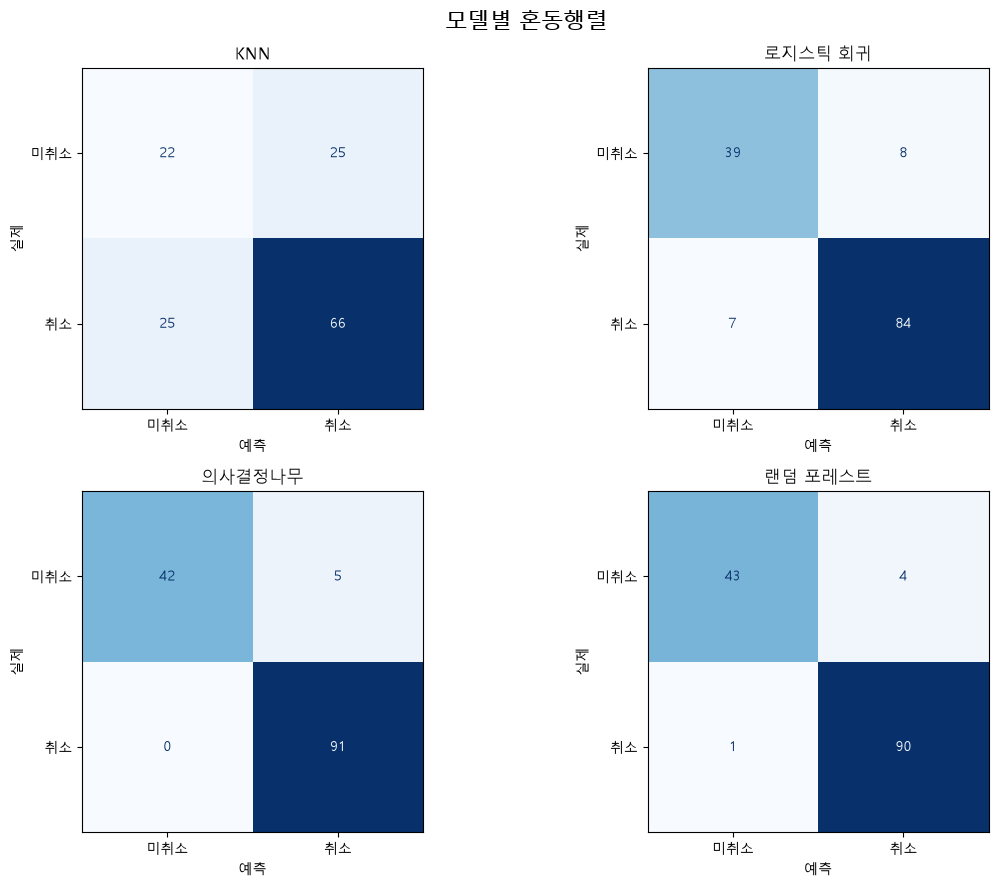

In [91]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Windows 기본 한글 글꼴
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

print("전체 데이터:", len(df), "건 / 테스트 데이터:", len(y_test), "건")
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

plots = [
    (knn_pred, "KNN", axes[0, 0]),
    (log_pred, "로지스틱 회귀", axes[0, 1]),
    (tree_pred, "의사결정나무", axes[1, 0]),
    (forest_pred, "랜덤 포레스트", axes[1, 1])
]

for pred, title, ax in plots:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["미취소", "취소"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("예측")
    ax.set_ylabel("실제")

fig.suptitle("모델별 혼동행렬", fontsize=16)
plt.tight_layout()
plt.show()

## 11. 취소와 관련된 예약 특성 살펴보기
아래 결과는 취소와 함께 나타나는 특성을 찾는 탐색 분석입니다. 연관성만으로 취소의 원인이라고 단정할 수는 없습니다.

### 예약 유형별 취소율
표본 수와 취소율을 함께 확인해 특정 유형의 취소가 많아 보이는 이유가 표본 수 때문인지 살펴봅니다.

In [92]:
for col in ["deposit_type", "market_segment", "customer_type", "hotel"]:
    print("\n", col)
    display(df.groupby(col)["is_canceled"].agg(예약건수="count", 취소율="mean").sort_values("취소율", ascending=False).round(3))


 deposit_type


,예약건수,취소율
deposit_type,,
No Deposit,159,0.925
Non Refund,148,0.541
Refundable,146,0.507
Unknown,4,0.250



 market_segment


,예약건수,취소율
market_segment,,
Agent,122,0.697
Corporate,108,0.657
Offline,104,0.654
Online,123,0.634



 customer_type


,예약건수,취소율
customer_type,,
Group,148,0.939
Transient,159,0.560
Contract,150,0.493



 hotel


,예약건수,취소율
hotel,,
City Hotel,236,0.695
Resort Hotel,221,0.624


### 취소 여부에 따른 예약 기간과 요금 비교
예약 시점이 숙박일보다 얼마나 앞섰는지(lead_time)와 객실 요금(ADR)을 비교합니다.

,lead_time,adr,special_requests,previous_cancellations
is_canceled,,,,
0,135.8,224.4,2.1,1.7
1,205.0,231.7,2.0,3.0


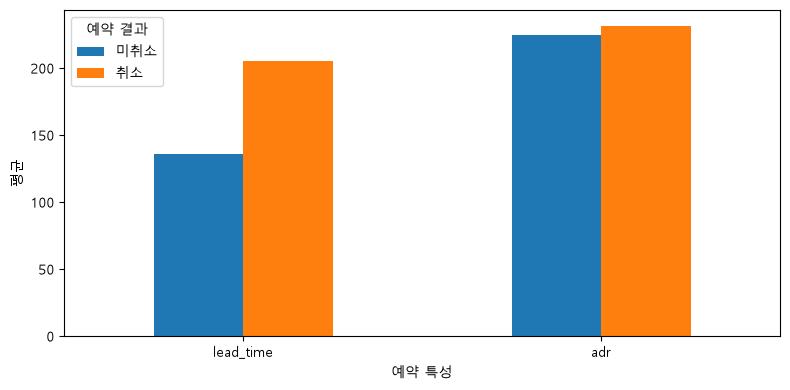

In [93]:
display(df.groupby("is_canceled")[["lead_time", "adr", "special_requests", "previous_cancellations"]].mean().round(1))

df.groupby("is_canceled")[["lead_time", "adr"]].mean().T.plot(kind="bar", figsize=(8, 4))
plt.xticks(rotation=0)
plt.xlabel("예약 특성")
plt.ylabel("평균")
plt.legend(["미취소", "취소"], title="예약 결과")
plt.tight_layout()
plt.show()

### 랜덤 포레스트에서 중요하게 사용된 변수
중요도가 높은 변수는 모델 예측에 많이 쓰였다는 뜻이며, 그 자체로 원인이라는 의미는 아닙니다.

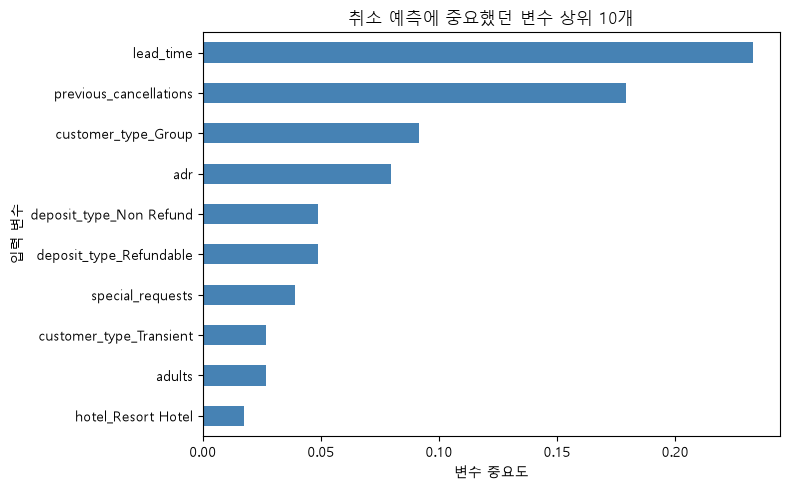

In [94]:
importance = pd.Series(forest_model.feature_importances_, index=X_train_encoded.columns)
importance = importance.sort_values().tail(10)
importance.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.xlabel("변수 중요도")
plt.ylabel("입력 변수")
plt.title("취소 예측에 중요했던 변수 상위 10개")
plt.tight_layout()
plt.show()

**해석할 때:** 취소율이 높은 예약 유형과 중요도가 높은 변수를 개선 후보로 삼되, 표본 수를 확인하고 추가 데이터나 실제 고객 사유로 검증하세요. 이 데이터만으로 취소 이유를 확정할 수는 없습니다.